# Étape 6 : Cascade regex + DrBERT

Deuxième approche. L'idée est de ne pas faire passer tous les documents dans DrBERT :
1. la regex de `preproc.py` (V1) cherche les mentions de tabac ;
2. si elle ne trouve rien, le document est classé directement « Non mentionné » ;
3. sinon, DrBERT prédit la classe : sur le document entier s'il fait au plus 510 tokens, sinon sur des fenêtres de 50 tokens autour des mentions (comme dans le notebook 05).

La regex sert à ne rien rater (rappel) et DrBERT à corriger ses erreurs (précision). Un document tabac que la regex ne capte pas est forcément mal classé. En revanche, un document « Non mentionné » capté par erreur (par exemple « sevrage en oxygène ») peut encore être classé « Non mentionné » par DrBERT. Ces faux positifs sont donc gardés dans le train, pour que DrBERT apprenne à les rejeter.

L'évaluation se fait sur les 120 documents du test (regex + DrBERT), avec le même split que les autres notebooks.

## Installation et configuration

In [1]:
%pip install -q "transformers>=4.48" "accelerate>=0.34" sentencepiece protobuf pyarrow

In [ ]:
import gc, json, os, re, sys, time, warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

import transformers
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup, set_seed
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score, classification_report, cohen_kappa_score,
                             confusion_matrix, f1_score, precision_recall_fscore_support)

warnings.filterwarnings("ignore", category=FutureWarning)
transformers.logging.set_verbosity_error()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| transformers", transformers.__version__, "| device :", DEVICE)
if DEVICE == "cuda":
    print(torch.cuda.get_device_name(0))
else:
    print("Pas de GPU")

# calcul en fp16 sur GPU pour aller plus vite et prendre moins de mémoire
USE_AMP = DEVICE == "cuda"

torch 2.14.1+cu130 | transformers 5.22.1 | device : cuda
Tesla T4


In [3]:
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = "/content/drive/MyDrive/stage_m2"
else:
    BASE_DIR = "."

# preproc.py et rules.py sont à la racine du projet (en local et sur le Drive)
sys.path.append(BASE_DIR)
from preproc import PARHAFPreprocessor
from rules import evaluer_algorithme
prep = PARHAFPreprocessor()

DATA_DIR = os.path.join(BASE_DIR, "data")
CSV_PATH = os.path.join(DATA_DIR, "annotated_corrected.csv")
PARQUET_PATH = os.path.join(DATA_DIR, "train-00000-of-00001.parquet")
RUN_NAME = "drbert_cascade"
OUT_DIR = os.path.join(BASE_DIR, "results", RUN_NAME)
os.makedirs(OUT_DIR, exist_ok=True)

SEED, TEST_SIZE, VAL_SIZE = 42, 0.2, 0.15   # même split que 04_ML

MODEL_CHECKPOINT = "Dr-BERT/DrBERT-7GB"
MAX_LEN = 512
CTX_TOKENS = 50   # tokens gardés de chaque côté d'une mention
ADD_TOXIQUE = False   # motif « pas de toxique », voir partie 6.3

EPOCHS, LR, WEIGHT_DECAY, WARMUP_RATIO = 10, 2e-5, 0.01, 0.1
TRAIN_BS, GRAD_ACC, EVAL_BS = 8, 2, 32

set_seed(SEED)
assert os.path.exists(CSV_PATH), CSV_PATH

Mounted at /content/drive


## 6.1 Données et split train / test

Même chargement et même split que dans le notebook 05 (et que `04_ML.ipynb`) : 477 documents en train, 120 en test. Le texte brut avec ponctuation est récupéré dans le parquet PARHAF avec `preproc.py`, et 15 % du train sert de validation.

In [4]:
df = pd.read_csv(CSV_PATH)[["id", "text", "label"]].copy()
df["label"] = df["label"].astype(str).str.strip()

le = LabelEncoder()
df["label_id"] = le.fit_transform(df["label"])
CLASSES = list(le.classes_)
NUM_LABELS = len(CLASSES)
ID2LABEL = dict(enumerate(CLASSES))
LABEL2ID = {c: i for i, c in ID2LABEL.items()}

# même split que 04_ML
idx_train, idx_test = train_test_split(df.index.values, test_size=TEST_SIZE, random_state=SEED,
                                       stratify=df["label_id"])

# texte brut du parquet, avec les mêmes id que le CSV (créés par explode_cols de preproc.py)
raw = prep.explode_cols(pd.read_parquet(PARQUET_PATH))
raw_text = df["id"].astype(str).map(dict(zip(raw["id"].astype(str), raw["text"])))
assert raw_text.notna().all(), "certains id du CSV ne sont pas dans le parquet"

# vérification : nettoyé avec clean_text, le texte brut doit redonner le texte du CSV
cleaned = prep.clean_text(pd.DataFrame({"text": raw_text}))["text"]
print(f"{(cleaned == df['text']).sum()}/{len(df)} textes identiques au CSV après nettoyage")
df["text"] = raw_text
del raw

df_train_full = df.loc[idx_train].copy()
df_test = df.loc[idx_test].copy()
df_train, df_val = train_test_split(df_train_full, test_size=VAL_SIZE, random_state=SEED,
                                    stratify=df_train_full["label_id"])

print(f"Train : {len(df_train)} | Validation : {len(df_val)} | Test : {len(df_test)}")
display(pd.DataFrame({s: d["label"].value_counts() for s, d in
                      [("train", df_train), ("val", df_val), ("test", df_test)]}).loc[CLASSES])

587/597 textes identiques au CSV après nettoyage
Train : 405 | Validation : 72 | Test : 120


,train,val,test
label,,,
Ancien fumeur,52,10,16
Fumeur actuel,63,11,18
Non mentionné,204,36,61
Non-fumeur,86,15,25


## 6.2 Fonctions utilitaires

Ces fonctions sont les mêmes dans les notebooks 05, 06 et 07 :
- `make_batch` et `predict_probs` : padding des séquences et prédiction, **dans l'ordre des séquences** ;
- `doc_probs` : regroupement des séquences d'un même document (moyenne des probabilités) ;
- `train_model` : la boucle d'entraînement, avec une cross-entropy pondérée par classe à cause du déséquilibre des labels. À la fin de chaque epoch on calcule le F1 macro de la validation par document, et on garde les poids de la meilleure epoch ;
- `evaluate_and_save` : l'évaluation sur le test (affichage avec `evaluer_algorithme` de `rules.py`), qui sauvegarde les prédictions et un `metrics.json` pour le notebook 08.

On n'utilise plus le `Trainer` de HuggingFace : avec l'option `group_by_length`, il changeait l'ordre des documents de validation, et les prédictions étaient comparées aux labels d'autres documents. Le F1 de validation était donc faux et la meilleure epoch choisie au hasard. Avec une boucle écrite à la main, on voit exactement ce qui se passe.

In [5]:
def make_batch(records, pad_to=None):
    # complète les séquences avec du padding pour qu'elles aient la même longueur
    batch = tokenizer.pad({"input_ids": [r["input_ids"] for r in records]}, return_tensors="pt",
                          padding="max_length" if pad_to else "longest", max_length=pad_to)
    batch["labels"] = torch.tensor([r["label_id"] for r in records])
    return batch


@torch.no_grad()
def predict_probs(model, records, batch_size, pad_to=None):
    # probabilités de chaque séquence, dans le même ordre que records
    model.eval()
    probs = []
    for i in range(0, len(records), batch_size):
        batch = make_batch(records[i:i + batch_size], pad_to)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(input_ids=batch["input_ids"].to(DEVICE),
                           attention_mask=batch["attention_mask"].to(DEVICE)).logits
        probs.append(torch.softmax(logits.float(), dim=-1).cpu().numpy())
    return np.concatenate(probs)


def doc_probs(records, probs):
    # un document peut donner plusieurs séquences : on fait la moyenne de leurs probabilités
    doc_ids = [r["doc_id"] for r in records]
    return pd.DataFrame(probs, columns=CLASSES).groupby(doc_ids, sort=False).mean()


def scores(y_true, y_pred):
    return {"f1_macro": f1_score(y_true, y_pred, average="macro"),
            "accuracy": accuracy_score(y_true, y_pred),
            "kappa": cohen_kappa_score(y_true, y_pred)}


def get_class_weights(label_ids):
    # poids "balanced" : une classe rare compte plus dans la loss
    counts = np.bincount(label_ids, minlength=NUM_LABELS)
    weights = len(label_ids) / (NUM_LABELS * np.maximum(counts, 1))
    print("Poids des classes :", {c: round(float(w), 3) for c, w in zip(CLASSES, weights)})
    return torch.tensor(weights, dtype=torch.float32)


def train_model(model, train_records, val_score):
    # val_score(model) renvoie le F1 macro, l'accuracy et le kappa de la validation, par document
    loader = DataLoader(train_records, batch_size=TRAIN_BS, shuffle=True, collate_fn=make_batch)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    n_updates = EPOCHS * int(np.ceil(len(loader) / GRAD_ACC))
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * n_updates), n_updates)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    class_weights = get_class_weights([r["label_id"] for r in train_records]).to(DEVICE)

    history, best_f1, best_weights = [], -1, None
    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss = 0
        for step, batch in enumerate(loader, start=1):
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                logits = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).logits
            loss = F.cross_entropy(logits.float(), batch["labels"], weight=class_weights)
            scaler.scale(loss / GRAD_ACC).backward()
            total_loss += loss.item()

            # on met à jour les poids tous les GRAD_ACC batchs (accumulation de gradient)
            if step % GRAD_ACC == 0 or step == len(loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()
                scheduler.step()
                optimizer.zero_grad()

        val = val_score(model)
        history.append({"epoch": epoch, "loss_train": total_loss / len(loader), **val})
        print(f"epoch {epoch:2d} | loss train {history[-1]['loss_train']:.4f} | "
              f"F1 val {val['f1_macro']:.4f} | accuracy val {val['accuracy']:.4f} | kappa val {val['kappa']:.4f}")

        # on garde une copie des poids de la meilleure epoch
        if val["f1_macro"] > best_f1:
            best_f1 = val["f1_macro"]
            best_weights = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_weights)
    return pd.DataFrame(history), best_f1


def evaluate_and_save(name, doc_ids, y_true, y_pred, probs, extra_cols=None, infos=None):
    # affiche les résultats du test et les sauvegarde pour le notebook 08
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    labels = np.arange(NUM_LABELS)
    evaluer_algorithme([ID2LABEL[i] for i in y_true], [ID2LABEL[i] for i in y_pred], name, CLASSES)

    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, average="macro", zero_division=0)
    acc = accuracy_score(y_true, y_pred)
    kappa = cohen_kappa_score(y_true, y_pred)
    print(f"F1 macro : {f1:.4f} | Accuracy : {acc:.4f} | Précision : {prec:.4f} | Rappel : {rec:.4f}")

    pred_df = pd.DataFrame({"doc_id": list(doc_ids),
                            "y_true": [ID2LABEL[i] for i in y_true], "y_pred": [ID2LABEL[i] for i in y_pred],
                            "y_true_id": y_true, "y_pred_id": y_pred})
    for j, c in enumerate(CLASSES):
        pred_df[f"proba_{c}"] = np.asarray(probs)[:, j]
    for col, values in (extra_cols or {}).items():
        pred_df[col] = list(values)
    pred_df.to_csv(os.path.join(OUT_DIR, "predictions_test.csv"), index=False)

    report = classification_report(y_true, y_pred, labels=labels, target_names=CLASSES, output_dict=True, zero_division=0)
    metrics = {
        "Modèle": name, "run_name": RUN_NAME, "timestamp": datetime.now().isoformat(timespec="seconds"),
        "n_test_docs": len(y_true), "classes": CLASSES,
        "Accuracy": round(acc, 4), "Precision (macro)": round(prec, 4), "Recall (macro)": round(rec, 4),
        "F1-score (macro)": round(f1, 4), "kappa": round(kappa, 4),
        "per_class": {c: {k: round(v, 4) for k, v in report[c].items()} for c in CLASSES},
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels).tolist(),
        **(infos or {}),
    }
    with open(os.path.join(OUT_DIR, "metrics.json"), "w", encoding="utf-8") as f:
        json.dump(metrics, f, ensure_ascii=False, indent=2, default=float)
    return pred_df


def vram_peak_gb():
    return round(torch.cuda.max_memory_allocated() / 1024**3, 2) if DEVICE == "cuda" else None

## 6.3 Amélioration de la regex

La regex de `preproc.py` capte trop de choses :
- `\bsevr` attrape tous les sevrages (oxygène, ventilation, alcool, CEC...), c'est la principale source de faux positifs ;
- `\bpaquets?\b` capte aussi « paquet vasculo-nerveux » ;
- `\d\s*PA\b` est insensible à la casse.

Dans la version 2 : `PA` seulement en majuscules après un nombre, `paquet` seulement avec une quantité ou « paquets-années », et `sevr*` seulement s'il y a un terme lié au tabac à moins de 80 caractères et pas de mot comme oxygène, O2 ou alcool juste après.

On a aussi essayé un motif « pas de toxique » (`ADD_TOXIQUE`) : certains documents de ce type ont été annotés Non-fumeur, mais il capte aussi beaucoup de Non mentionné, donc il est désactivé.

La comparaison entre les deux versions est faite uniquement sur le train.

**Choix du filtre.** La V2 est plus précise, mais c'est justement un problème pour la cascade : elle ne laisse passer presque aucun document « Non mentionné » (1 seul dans le train). DrBERT n'a alors pas d'exemples pour apprendre à rejeter les faux positifs, et le poids de cette classe dans la loss devient énorme (≈ 50). On utilise donc la **V1** comme filtre : elle a le même rappel (98.7 %) et laisse passer environ 18 faux positifs dans le train (surtout des « sevrage » non tabagiques), que DrBERT apprend à classer « Non mentionné ». La V2 est gardée ici seulement pour la comparaison.

In [6]:
# regex de preproc.py (version 1)
RE_TABAC_V1 = re.compile(prep.re_tabac, flags=re.IGNORECASE)

RE_TABAC_CORE_V2 = re.compile(r"""
    \btabac\b | \btabagisme | \btabagique | intoxication\s+tabagique
  | (?:alcoolo|éthylo|ethylo)[-\s]?tabagi | post[-\s]?tabagi
  | \bfumeu(?:r|se)s?\b | \bnon[-\s]?fumeu(?:r|se) | \b(?:ancien(?:ne)?|ex)[-\s]?fumeu(?:r|se)
  | jamais\s+fum | \bfum(?:e|ait|aient|er|é)\b
  | \bcigarettes?\b | \bcig\b | \bcigares?\b | \bvapot | \be-cigarettes? | \bla\s+pipe\b | nicotin
  | (?-i:\d\s*PA\b)
  | \d+(?:[.,]\d+)?\s*paquets? | paquets?[-\s]?ann[ée]es? | paquets?\s*(?:/|par)\s*(?:j\b|jour)
  | sevrage\s+tabagique | tabacolog
""", re.IGNORECASE | re.VERBOSE)

RE_SEVR = re.compile(r"\bsevr\w*", re.IGNORECASE)
# sevrage d'autre chose que le tabac (dans les mots qui suivent)
RE_SEVR_NON_TABAC = re.compile(
    r"^\W*(?:\w+\W+){0,3}?(?:oxyg|o2\b|ventil|vni\b|respirat|circulation|cec\b|extra|alcool|éthyl|ethyl|"
    r"opi|morphin|benzo|cortico|dialys|drain|sonde|nutrition|amines?\b|noradr|catécho|simple)",
    re.IGNORECASE)
RE_TOXIQUE = re.compile(
    r"\b(?:pas|aucune?|sans|ni|nie|absence)\b(?:\W+\w+){0,4}?\W+toxiques?\b|\btoxiques?\W+(?:0|non|aucun|néant|nie)\b",
    re.IGNORECASE)


def find_mentions_v1(text):
    return [(m.start(), m.end(), m.group(0).lower()) for m in RE_TABAC_V1.finditer(text) if m.end() > m.start()]


def find_mentions_v2(text):
    spans = [(m.start(), m.end(), m.group(0).lower()) for m in RE_TABAC_CORE_V2.finditer(text)]
    for m in RE_SEVR.finditer(text):
        if RE_SEVR_NON_TABAC.search(text[m.end():m.end() + 60]):
            continue
        if RE_TABAC_CORE_V2.search(text[max(0, m.start() - 80):m.end() + 80]):
            spans.append((m.start(), m.end(), "sevr* (contexte tabac)"))
    if ADD_TOXIQUE:
        spans += [(m.start(), m.end(), "toxique (négation)") for m in RE_TOXIQUE.finditer(text)]
    return sorted(spans)


def keyword(term):
    return re.sub(r"\d+([.,]\d+)?", "<n>", term)


comp = df_train_full[["id", "label"]].copy()
comp["v1"] = df_train_full["text"].map(lambda t: len(find_mentions_v1(t)) > 0)
comp["v2"] = df_train_full["text"].map(lambda t: len(find_mentions_v2(t)) > 0)
comp["positif"] = comp["label"] != "Non mentionné"

tab = pd.DataFrame({
    "docs": comp.groupby("label").size(),
    "captés V1": comp.groupby("label")["v1"].sum(),
    "captés V2": comp.groupby("label")["v2"].sum(),
}).loc[CLASSES]
display(tab)

pos = comp[comp.positif]
neg = comp[~comp.positif]
print(f"Rappel sur les documents tabac : V1 {pos.v1.mean():.1%} | V2 {pos.v2.mean():.1%}")
print(f"Faux positifs (Non mentionné captés) : V1 {neg.v1.sum()} | V2 {neg.v2.sum()}")
print(f"Documents tabac perdus avec V2 : {(pos.v1 & ~pos.v2).sum()} | gagnés : {(~pos.v1 & pos.v2).sum()}")

# mots-clés qui déclenchent les faux positifs
fp_terms = lambda f: pd.Series([keyword(t) for txt in df_train_full.loc[df_train_full["label"] == "Non mentionné", "text"]
                                for (_, _, t) in f(txt)]).value_counts()
display(pd.concat({"V1": fp_terms(find_mentions_v1), "V2": fp_terms(find_mentions_v2)}, axis=1).fillna(0).astype(int).head(15))

# documents captés seulement par le motif "toxique"
tox = df_train_full["text"].map(lambda t: bool(RE_TOXIQUE.search(t)))
display((tox & ~comp["v2"]).groupby(comp["label"]).sum().loc[CLASSES].to_frame("captés par 'toxique' seulement"))

,docs,captés V1,captés V2
label,,,
Ancien fumeur,62,62,62
Fumeur actuel,74,73,73
Non mentionné,240,18,1
Non-fumeur,101,99,99


Rappel sur les documents tabac : V1 98.7% | V2 98.7%
Faux positifs (Non mentionné captés) : V1 18 | V2 1
Documents tabac perdus avec V2 : 0 | gagnés : 0


,V1,V2
sevr,27,0
paquet,5,0
tabagique,1,0
tabagisme,1,1
sevr* (contexte tabac),0,1
sevrage tabagique,0,1


,captés par 'toxique' seulement
label,
Ancien fumeur,0
Fumeur actuel,0
Non mentionné,7
Non-fumeur,1


## 6.4 Filtrage et construction des séquences

La regex V1 est appliquée à chaque split :
- pas de mention : prédiction « Non mentionné » directement ;
- au moins une mention et document de 510 tokens ou moins : le document entier est donné à DrBERT ;
- au moins une mention et document plus long : fenêtres de 50 tokens autour des mentions, comme dans le notebook 05.

In [7]:
def load_tokenizer(ckpt):
    # avec transformers 5, AutoTokenizer n'arrive pas toujours à charger le tokenizer de DrBERT
    try:
        return AutoTokenizer.from_pretrained(ckpt, use_fast=True)
    except Exception:
        from transformers import PreTrainedTokenizerFast
        return PreTrainedTokenizerFast.from_pretrained(ckpt)


tokenizer = load_tokenizer(MODEL_CHECKPOINT)
assert tokenizer.is_fast   # nécessaire pour les offsets
BODY_LEN = MAX_LEN - 2   # place pour les tokens <s> et </s>
print(type(tokenizer).__name__, "| BODY_LEN =", BODY_LEN)
NM_ID = LABEL2ID["Non mentionné"]

config.json:   0%|          | 0.00/641 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/653 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B /  791kB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.36M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/353 [00:00<?, ?B/s]

TokenizersBackend | BODY_LEN = 510


In [8]:
def encode_doc(text):
    enc = tokenizer(text, add_special_tokens=False, return_offsets_mapping=True, truncation=False, verbose=False)
    return enc["input_ids"], enc["offset_mapping"]


def char_to_token_spans(char_spans, offsets):
    # positions en caractères -> positions en tokens
    starts = np.array([o[0] for o in offsets])
    ends = np.array([o[1] for o in offsets])
    spans = []
    for cs, ce in char_spans:
        idx = np.where((starts < ce) & (ends > cs))[0]
        if len(idx):
            spans.append((int(idx[0]), int(idx[-1])))
    return spans


def merge_windows(tok_spans, n_tokens, ctx):
    # une fenêtre de ctx tokens de chaque côté de chaque mention, fusionnées si elles se chevauchent
    wins = sorted((max(0, a - ctx), min(n_tokens, b + 1 + ctx)) for a, b in tok_spans)
    merged = []
    for s, e in wins:
        if merged and s <= merged[-1][1]:
            merged[-1][1] = max(merged[-1][1], e)
        else:
            merged.append([s, e])
    return merged


def pack_segments(segments, body_len, sep_id):
    # met les fenêtres bout à bout (séparées par </s>) sans dépasser body_len
    seqs, cur = [], []
    for seg in segments:
        for i in range(0, len(seg), body_len):
            piece = list(seg[i:i + body_len])
            need = len(piece) + (1 if cur else 0)
            if len(cur) + need <= body_len:
                cur = cur + ([sep_id] if cur else []) + piece
            else:
                seqs.append(cur)
                cur = piece
    if cur:
        seqs.append(cur)
    return seqs


def window_sequences(ids, offsets, char_spans, ctx):
    tok_spans = char_to_token_spans(char_spans, offsets)
    wins = merge_windows(tok_spans, len(ids), ctx)
    return pack_segments([ids[s:e] for s, e in wins], BODY_LEN, tokenizer.sep_token_id)


def with_special(body_ids):
    return [tokenizer.cls_token_id] + list(body_ids) + [tokenizer.sep_token_id]

In [9]:
def cascade_records(frame):
    recs, infos = [], []
    for r in frame.itertuples(index=False):
        mentions = find_mentions_v1(r.text)
        info = {"doc_id": r.id, "label_id": int(r.label_id), "n_mentions": len(mentions)}
        if not mentions:
            infos.append({**info, "routed_by": "regex", "n_seqs": 0})
            continue
        ids, offsets = encode_doc(r.text)
        if len(ids) <= BODY_LEN:
            kind, bodies = "full", [ids]   # document court : gardé en entier
        else:
            kind, bodies = "window", window_sequences(ids, offsets, [(s, e) for s, e, _ in mentions], CTX_TOKENS)
        if not bodies:   # sécurité : mention trouvée mais aucun token correspondant
            kind, bodies = "window", [ids[:BODY_LEN]]
        recs += [{"doc_id": r.id, "label_id": int(r.label_id), "input_ids": with_special(b)} for b in bodies]
        infos.append({**info, "routed_by": "drbert", "seq_type": kind, "n_seqs": len(bodies),
                      "n_doc_tokens": len(ids)})
    return recs, pd.DataFrame(infos)


train_records, train_info = cascade_records(df_train)
val_records, val_info = cascade_records(df_val)
t0 = time.perf_counter()
test_records, test_info = cascade_records(df_test)
prep_test_s = time.perf_counter() - t0

for name, info, recs in [("train", train_info, train_records), ("val", val_info, val_records), ("test", test_info, test_records)]:
    routed = info[info.routed_by == "drbert"]
    print(f"{name:5s} : {len(info)} docs | envoyés à DrBERT : {len(routed)} ({len(recs)} séquences, "
          f"{np.mean([len(r['input_ids']) for r in recs]):.0f} tokens en moyenne) | classés par la regex : {len(info) - len(routed)}")

print("\nDocuments envoyés à DrBERT, en entier (full) ou en fenêtres (window) :")
display(pd.DataFrame({n: i["seq_type"].value_counts() for n, i in
                      [("train", train_info), ("val", val_info), ("test", test_info)]}).fillna(0).astype(int))

print("\nDocuments envoyés à DrBERT par label :")
display(pd.DataFrame({n: i[i.routed_by == "drbert"]["label_id"].map(ID2LABEL).value_counts()
                      for n, i in [("train", train_info), ("val", val_info), ("test", test_info)]}).reindex(CLASSES).fillna(0).astype(int))

train : 405 docs | envoyés à DrBERT : 214 (218 séquences, 201 tokens en moyenne) | classés par la regex : 191
val   : 72 docs | envoyés à DrBERT : 38 (38 séquences, 172 tokens en moyenne) | classés par la regex : 34
test  : 120 docs | envoyés à DrBERT : 61 (61 séquences, 184 tokens en moyenne) | classés par la regex : 59

Documents envoyés à DrBERT, en entier (full) ou en fenêtres (window) :


,train,val,test
seq_type,,,
window,171,33,53
full,43,5,8



Documents envoyés à DrBERT par label :


,train,val,test
label_id,,,
Ancien fumeur,52,10,16
Fumeur actuel,62,11,18
Non mentionné,15,3,3
Non-fumeur,85,14,24


## 6.5 Entraînement

La meilleure epoch est choisie sur le F1 macro de toute la validation, en comptant aussi les documents classés « Non mentionné » par la regex. C'est la même métrique que celle utilisée à la fin sur le test.

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

Poids des classes : {'Ancien fumeur': 1.048, 'Fumeur actuel': 0.826, 'Non mentionné': 3.633, 'Non-fumeur': 0.641}
epoch  1 | loss train 1.3999 | F1 val 0.4532 | accuracy val 0.6250 | kappa val 0.4527
epoch  2 | loss train 1.2139 | F1 val 0.4381 | accuracy val 0.6528 | kappa val 0.4751
epoch  3 | loss train 0.9218 | F1 val 0.5432 | accuracy val 0.6944 | kappa val 0.5391
epoch  4 | loss train 0.6983 | F1 val 0.5348 | accuracy val 0.7083 | kappa val 0.5504
epoch  5 | loss train 0.4840 | F1 val 0.6613 | accuracy val 0.7917 | kappa val 0.6824
epoch  6 | loss train 0.2997 | F1 val 0.6839 | accuracy val 0.8056 | kappa val 0.7009
epoch  7 | loss train 0.1390 | F1 val 0.7182 | accuracy val 0.8056 | kappa val 0.7051
epoch  8 | loss train 0.0793 | F1 val 0.7642 | accuracy val 0.8472 | kappa val 0.7669
epoch  9 | loss train 0.0451 | F1 val 0.7867 | accuracy val 0.8611 | kappa val 0.7884
epoch 10 | loss train 0.0310 | F1 val 0.7867 | accuracy val 0.8611 | kappa val 0.7884

Entraînement : 1.0 min | 

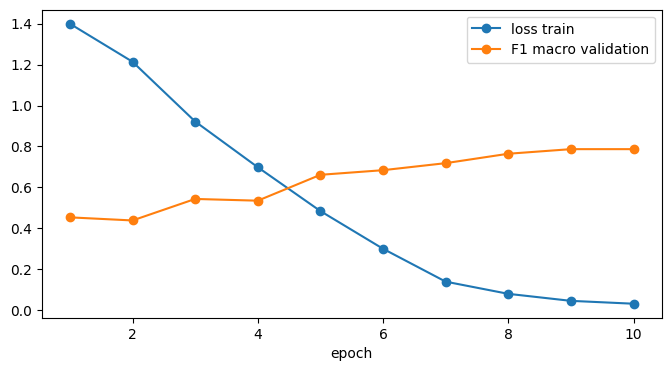

In [10]:
set_seed(SEED)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_CHECKPOINT, num_labels=NUM_LABELS, id2label=ID2LABEL, label2id=LABEL2ID).to(DEVICE)


def cascade_predict(model, frame, records):
    # DrBERT pour les documents captés par la regex, « Non mentionné » pour les autres
    probs = doc_probs(records, predict_probs(model, records, EVAL_BS))
    no_mention = np.eye(NUM_LABELS)[NM_ID]
    return np.vstack([probs.loc[d].values if d in probs.index else no_mention for d in frame["id"]])


def val_score(model):
    return scores(df_val["label_id"], cascade_predict(model, df_val, val_records).argmax(1))


if DEVICE == "cuda":
    torch.cuda.reset_peak_memory_stats()
t0 = time.perf_counter()
history, best_val_f1 = train_model(model, train_records, val_score)
train_time_s = time.perf_counter() - t0
peak_vram_train = vram_peak_gb()

print(f"\nEntraînement : {train_time_s / 60:.1f} min | VRAM max : {peak_vram_train} Go")
print(f"Meilleur F1 macro en validation : {best_val_f1:.4f} (epoch {history['f1_macro'].idxmax() + 1})")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history["epoch"], history["loss_train"], marker="o", label="loss train")
ax.plot(history["epoch"], history["f1_macro"], marker="o", label="F1 macro validation")
ax.set_xlabel("epoch")
ax.legend()
plt.show()

## 6.6 Évaluation sur le test (regex + DrBERT)

,valeur
n_test_routed_to_drbert,61.0000
n_test_classified_by_regex,59.0000
filter_false_negatives,1.0000
filter_fn_rate_on_positives,0.0169
share_of_errors_due_to_filter,0.0714
filter_residual_false_positives,3.0000
drbert_only_f1_macro,0.7804
drbert_only_accuracy,0.7869


Cascade regex V1 + DrBERT :
Coefficient de Kappa : 0.8223
Niveau d'accord (Landis & Koch) : Presque parfait

Rapport de classification
               precision    recall  f1-score   support

Ancien fumeur       0.76      0.81      0.79        16
Fumeur actuel       0.79      0.61      0.69        18
Non mentionné       0.98      0.98      0.98        61
   Non-fumeur       0.79      0.88      0.83        25

     accuracy                           0.88       120
    macro avg       0.83      0.82      0.82       120
 weighted avg       0.88      0.88      0.88       120



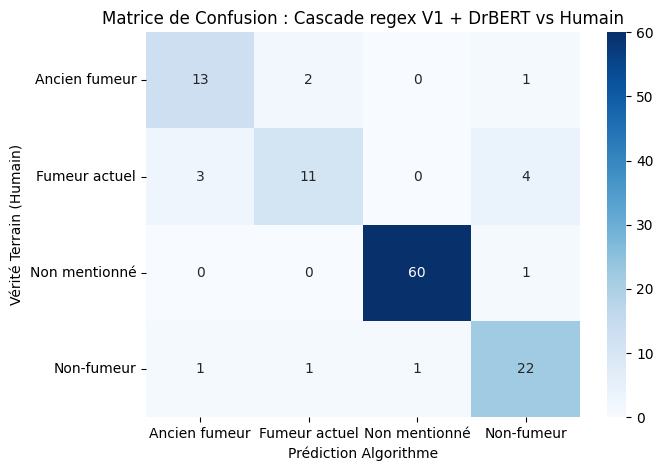




F1 macro : 0.8223 | Accuracy : 0.8833 | Précision : 0.8299 | Rappel : 0.8218
Inférence : 3.6 s | VRAM : 0.95 Go


In [11]:
if DEVICE == "cuda":
    torch.cuda.reset_peak_memory_stats()
t0 = time.perf_counter()
probs_doc = cascade_predict(model, df_test, test_records)
infer_time_s = time.perf_counter() - t0 + prep_test_s   # on compte aussi le temps de la regex
peak_vram_infer = vram_peak_gb()

info_test = test_info.set_index("doc_id").loc[df_test["id"]]
y_true = df_test["label_id"].values
y_pred = probs_doc.argmax(1)
routed = (info_test["routed_by"] == "drbert").values

# documents tabac que la regex n'a pas captés
positives = y_true != NM_ID
filter_fn = positives & ~routed
n_errors = (y_true != y_pred).sum()
filter_stats = {
    "n_test_routed_to_drbert": int(routed.sum()), "n_test_classified_by_regex": int((~routed).sum()),
    "filter_false_negatives": int(filter_fn.sum()),
    "filter_fn_rate_on_positives": round(filter_fn.sum() / max(positives.sum(), 1), 4),
    "share_of_errors_due_to_filter": round(filter_fn.sum() / max(n_errors, 1), 4),
    "filter_residual_false_positives": int((routed & ~positives).sum()),
    "drbert_only_f1_macro": round(f1_score(y_true[routed], y_pred[routed], average="macro",
                                           labels=range(NUM_LABELS), zero_division=0), 4),
    "drbert_only_accuracy": round(accuracy_score(y_true[routed], y_pred[routed]), 4),
}
display(pd.Series(filter_stats).to_frame("valeur"))

pred_df = evaluate_and_save(
    "Cascade regex V1 + DrBERT", df_test["id"].values, y_true, y_pred, probs_doc,
    extra_cols={"routed_by": info_test["routed_by"], "seq_type": info_test["seq_type"],
                "n_mentions": info_test["n_mentions"]},
    infos={"train_time_s": round(train_time_s, 1), "inference_time_s": round(infer_time_s, 2),
           "inference_ms_per_doc": round(1000 * infer_time_s / len(df_test), 1),
           "peak_vram_train_gb": peak_vram_train, "peak_vram_infer_gb": peak_vram_infer,
           **filter_stats, "best_val_f1_macro": round(best_val_f1, 4),
           "regex_filter": "V1 (preproc.py)",
           "config": {"model": MODEL_CHECKPOINT, "max_len": MAX_LEN, "ctx_tokens": CTX_TOKENS, "epochs": EPOCHS,
                      "lr": LR, "train_bs": TRAIN_BS, "grad_acc": GRAD_ACC, "seed": SEED,
                      "test_size": TEST_SIZE, "val_size": VAL_SIZE}},
)
print(f"Inférence : {infer_time_s:.1f} s | VRAM : {peak_vram_infer} Go")

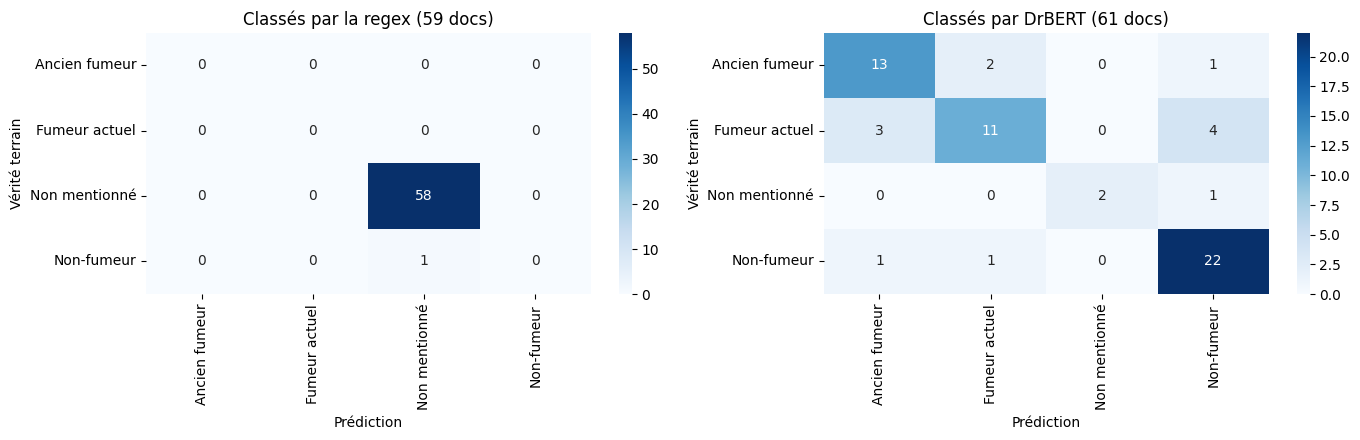

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, mask, title in [(axes[0], ~routed, "Classés par la regex"), (axes[1], routed, "Classés par DrBERT")]:
    cm = confusion_matrix(y_true[mask], y_pred[mask], labels=range(NUM_LABELS))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_title(f"{title} ({mask.sum()} docs)")
    ax.set_ylabel("Vérité terrain")
    ax.set_xlabel("Prédiction")
plt.tight_layout()
plt.show()